# SIADS 681: Health Analytics — Article Study Notes

Assigned reading · Week study guide · Research methods, algorithmic fairness, and health equity

Article: Obermeyer, Z., Powers, B., Vogeli, C., & Mullainathan, S. (2019). Dissecting racial bias in an algorithm used to manage the health of populations. Science, 366(6464), 447–453.

Central argument: An algorithm can accurately predict health care spending while systematically underestimating the health needs of Black patients. The problem is not necessarily the machine learning method itself, but the choice of what the model is trained to predict (the target label).

## 1. Research overview

| Component         | Description                                                                                                    |
| ----------------- | -------------------------------------------------------------------------------------------------------------- |
| Research problem  | Racial bias in an algorithm used to identify patients for additional care                                      |
| Primary question  | Why are Black patients with greater illness burdens assigned the same risk scores as healthier White patients? |
| Study design      | Retrospective observational analysis, with counterfactual simulations and alternative predictive models        |
| Population        | 49,618 Black and White patients at a large academic hospital                                                   |
| Data              | Insurance claims, electronic health records, laboratory results, and algorithmic risk scores                   |
| Main finding      | At the same predicted risk, Black patients were significantly sicker than White patients                       |
| Root cause        | Health care expenditures were used as a proxy for health needs                                                 |
| Proposed solution | Train models using health-related outcomes rather than relying exclusively on expenditures                     |

The authors examined a commercially deployed risk-prediction algorithm used to help allocate high-risk care management, including additional clinical attention and coordination for patients with complex needs.

The paper discusses an industry-wide class of algorithms estimated to affect roughly 200 million people annually. That estimate does not mean the study itself included 200 million patients.

## 2. How the algorithm works

```mermaid
graph TD
    A[Input features (X)] --> B(Predictive algorithm) --> C(Predicted cost → risk score) C --> D(55th–97th percentile) C--> D[Above 97th percentile]
```

Input features (X)

Prior-year diagnoses, procedures, medications, insurance type, demographics, and costs

Predictive algorithm

Learns patterns associated with future medical expenditures

Predicted cost → risk score

Used as an indicator of future health care needs

55th–97th percentile

Physician screening for possible enrollment

Above 97th percentile

Automatically identified for enrollment

### Where the bias enters

The intended goal was to identify patients with complex health needs, but the actual prediction target was future health care costs.

These are not equivalent:

- Health needs: How sick a patient is and how much clinical support they require.
- Health care costs: How much money is spent treating that patient.

A patient can be severely ill but generate relatively low spending because of barriers to accessing care.

Important: The original algorithm explicitly excluded race from its input features. Nevertheless, it produced racially unequal predictions of health needs.

## 3. Main findings and statistics

Original algorithm

# 17.7%

Black patients among those automatically identified at the 97th-percentile threshold

Bias-corrected simulation

# 46.5%

Black patients among those identified under a simulated equal-health threshold

Black patient representation at the automatic-identification threshold

Percent of patients identified at or above the 97th risk percentile who were Black.

![Black patient representation at the automatic-identification threshold.png](<attachment:Black patient representation at the automatic-identification threshold.png>)

Figure 1B, page 3. These are simulated changes in the racial composition of the high-risk group, not observed changes in actual program enrollment.

### Illness burden at the same risk score

At the 97th percentile, the researchers found:

| Measure                   | Black patients | White patients |
| ------------------------- | -------------- | -------------- |
| Active chronic conditions | 4.8            | 3.8            |

Black patients had 26.3% more chronic conditions despite receiving comparable predicted risk scores (P < 0.001).

### Costs at the same level of illness

At a given number of chronic conditions, Black patients generated approximately $1,801 less in annual medical expenditures than White patients. This difference was $1,144 when adjusting for the specific chronic illnesses.

This is the central mechanism: the algorithm interpreted lower spending as lower need, even though illness burden was comparable.

## 4. Understanding the paper's figures

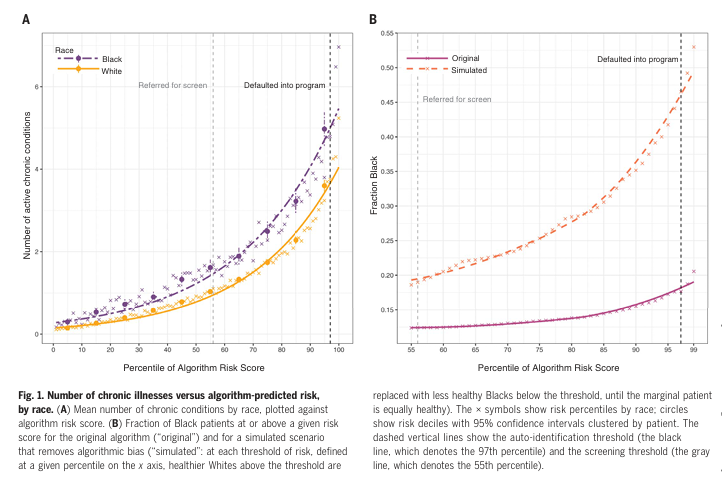 
> Figure 1 — Chronic conditions vs. predicted risk (page 3)

Black patients consistently have more chronic conditions at the same risk score. The second panel estimates how correcting this disparity changes representation in the high-risk group.

Interpretation: Risk scores underestimate Black patients' relative health needs.

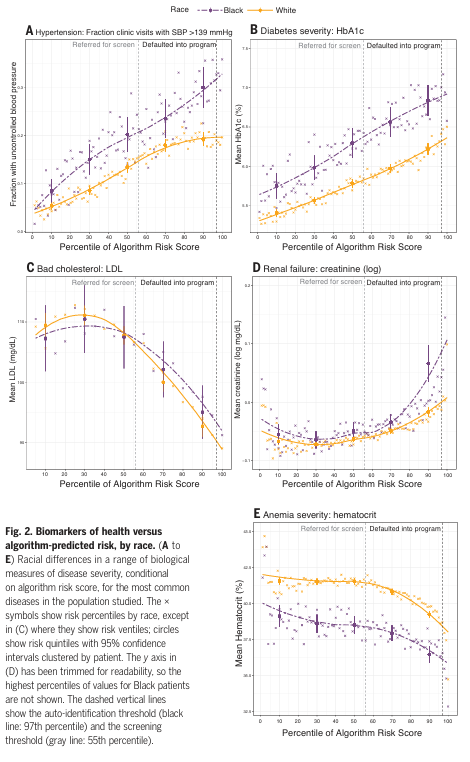
> Figure 2 — Clinical biomarkers (page 4)

The disparities persist when examining blood pressure, HbA1c, LDL cholesterol, creatinine, and hematocrit.

Interpretation: The findings are not limited to counts of diagnoses; clinical measurements also indicate worse health.

[Jake’s Machine Learning Blog - Replication Study - Dissecting Racial Bias in an Algorithm Used to Manage the Health of Populations](https://images.openai.com/static-rsc-4/jvtsOe0ELV6OOa0gxiunctrr8sJIdsvimqSiQ764TeGp0FwRQICiHk_cuQtFKxwgs1Qr-YaVFJLqsEpEzOFkXwZG_p6rSzspZvYZ7xWNASud9bJN8joiA3Js7rbW7tV01XyF-JxlK_Rr7fALtDME05dzwsjmqScWPf5sHUT5p94?purpose=inline)

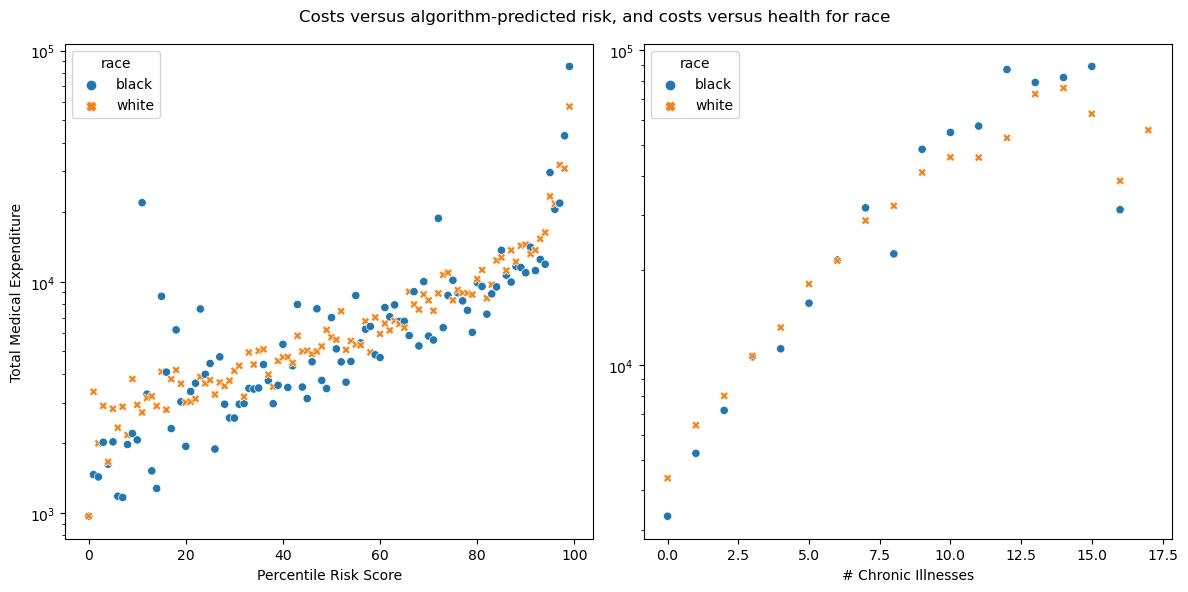
> Figure 3 — Costs vs. predicted risk and illness (page 5)

Panel A: Black and White patients have approximately equal expenditures at the same predicted risk.

Panel B: Black patients generate lower expenditures at the same level of illness.

Interpretation: The algorithm is reasonably calibrated for costs but not for health needs.

## 5. Key data science concepts

### A. Proxy variables and target labels

A target label (Y) is the outcome a supervised learning algorithm is trained to predict.

A proxy variable is a measurable substitute for a concept that may be difficult to observe directly.

In this study:

$$[ Y=\text{Future medical expenditures} ]$$

But the intended construct was:

$$[ H=\text{Patient health needs} ]$$

The researchers showed that predicting $$(Y)$$ accurately did not guarantee accurate prediction of $$(H)$$

Study takeaway: Before evaluating model performance, ask whether the prediction target actually represents the problem you are trying to solve.

### B. Algorithmic calibration

Calibration asks whether predicted risk corresponds to observed outcomes.

The authors examine whether, at a given risk score, Black and White patients have the same expected outcome.

For health:

$$[ E[H\mid R=r,B]=E[H\mid R=r,W] ]$$

Where:

- $(H)$: Observed health outcome
- $(R)$: Algorithmic risk score
- $(B)$: Black patients
- $(W)$: White patients
- $(E)$: Expected (average) value

The authors find this equality does not hold for health outcomes. It approximately holds for expenditures.

Therefore, the algorithm can be calibrated for its training target and still be unfair for the clinical decision it supports.

### C. Label choice bias

The article defines label choice bias through differences in who is classified as high-risk when different, defensible outcomes are predicted.

The researchers compared models trained on:

1. Total future medical costs
2. Avoidable future costs, including emergency visits and hospitalizations
3. Active chronic conditions

Each model was trained on a random two-thirds of the data and evaluated on the remaining one-third.

| Training label            | Black patients in highest-risk group |
| ------------------------- | ------------------------------------ |
| Total costs               | 14.1%                                |
| Avoidable costs           | 21.0%                                |
| Active chronic conditions | 26.7%                                |

These values come from Table 2, page 6.

Interpretation: Changing the target variable changes which patients the algorithm identifies, even when the predictive models are otherwise developed similarly.

### D. Structural inequality in training data

Historical data reflect the systems that generated them.

For example:
```mermaid
graph TD
    A[Barriers to health care access ] --> B(Lower utilization and expenditures relative to need) --> C(Lower predicted future spending) --> D(Lower algorithmic priority) --> E[Potential underallocation of care management]
```

The authors discuss barriers such as transportation, geography, competing work and caregiving responsibilities, and differential treatment within the health system. They do not experimentally isolate the contribution of each mechanism.

## 6. Role of human judgment

The researchers also examined whether physicians corrected the algorithm's bias during enrollment decisions.

Table 3 (page 6) reports the following Black patient representation:

| Enrollment strategy                                   | % Black |
| ----------------------------------------------------- | ------- |
| Observed physician-influenced enrollment              | 19.2%   |
| Random selection within predicted-cost bins           | 18.3%   |
| Select highest predicted health need within cost bins | 26.9%   |
| Select highest predicted cost overall                 | 17.2%   |
| Select worst predicted health overall                 | 29.2%   |

Physician decisions appeared to correct only a small portion of the disparity compared with selecting patients using a health-based prediction model.

Important distinction: Human review does not automatically eliminate algorithmic bias, particularly when reviewers rely on the algorithm's scores.

## 7. Proposed solutions

The researchers collaborated with the algorithm manufacturer after completing their initial independent analysis.

Their first proposed modification combined health prediction with cost prediction into a new target index, retaining the existing model infrastructure.

Reported reduction in bias

# 84%

The excess number of active chronic conditions among Black patients, conditional on risk score, decreased from 48,772 to 7,758 in the manufacturer's national-data analysis.

The authors argue that improving label selection can reduce bias without necessarily requiring race-specific model adjustments or entirely new machine learning methods.

The paper reports an initial corrective experiment and planned further development; it does not establish that every proposed improvement was subsequently deployed.

## 8. Strengths and limitations

| Strengths                                                    | Limitations                                                              |
| ------------------------------------------------------------ | ------------------------------------------------------------------------ |
| Examines a real, deployed commercial algorithm               | Primary analysis conducted within one academic health system             |
| Access to algorithm inputs, outputs, and subsequent outcomes | Main racial comparison focuses on Black and White patients               |
| Uses both diagnosis counts and clinical biomarkers           | Number of chronic conditions is not a complete measure of health         |
| Tests alternative prediction targets                         | Counterfactual simulations are not randomized intervention trials        |
| Manufacturer independently replicated key findings           | Cannot fully isolate every social mechanism driving spending differences |

A particularly important methodological distinction is that the researchers demonstrate disparities and investigate plausible mechanisms, but do not establish the causal contribution of each individual barrier to care.

## 9. Exam review: Concepts to remember

| Term                         | Plain-English definition                                                           |
| ---------------------------- | ---------------------------------------------------------------------------------- |
| Population health management | Coordinating care and resources across a patient population                        |
| Risk stratification          | Sorting patients into groups based on predicted future risk                        |
| Proxy variable               | A measurable stand-in for something harder to measure                              |
| Target label                 | The outcome a model learns to predict                                              |
| Calibration                  | Agreement between predicted risk and observed outcomes                             |
| Algorithmic bias             | Systematic disparities in algorithmic predictions or their consequences            |
| Comorbidity                  | Having multiple health conditions                                                  |
| Counterfactual simulation    | Estimating what would happen under an alternative decision rule                    |
| Structural inequality        | Systemic differences in access, opportunity, or treatment that shape observed data |
| Problem formulation          | Translating a real-world objective into a measurable prediction problem            |

## 10. Practice questions

Test your understanding

1\. 
Why was the algorithm racially biased even though race was excluded from its features?

2\. 
How could the algorithm be calibrated for costs but biased for health?

3\. 
What does the 17.7% to 46.5% result represent?

4\. 
What was the purpose of training models on three alternative labels?

5\. 
Did physician review eliminate the disparity?

6\. 
What is the main practical lesson for health data scientists?

## 11. Final takeaways for SIADS 681

- Prediction accuracy does not guarantee fairness. A model can perform well statistically while systematically disadvantaging a patient population.
- The target label matters as much as the algorithm. Cost is not necessarily an appropriate substitute for clinical need.
- Race-blind modeling is not automatically bias-free. Omitting a protected characteristic does not remove inequalities already embedded in the data.
- Health analytics requires domain knowledge. Clinical outcomes, access to care, and health system incentives must inform model development.
- Fairness must be evaluated in context. A model should be assessed against the clinical purpose and resource-allocation decisions it supports.

One-sentence exam answer: Obermeyer et al. (2019) demonstrate that using health care expenditures as a proxy for clinical need can embed structural racial inequalities into predictive algorithms, producing inequitable care-management recommendations even when the model is well calibrated for costs.

All statistics, interpretations of figures, and reported experimental results above are based on the uploaded article. The diagrams and simplified definitions are study aids.
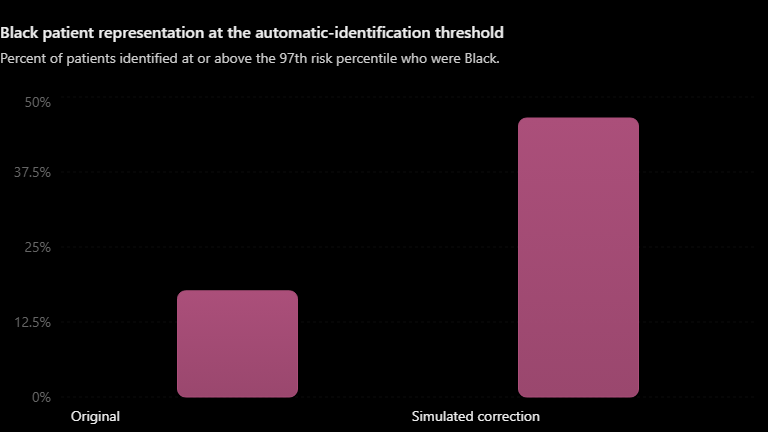